In [21]:
import pandas as pd
import numpy as np

df = pd.read_csv('New Explanation Evaluation_September 16, 2026_10.16.csv')
df = df.loc[2:]

df['Duration (in seconds)'] = pd.to_numeric(df['Duration (in seconds)'])

#Import demographics for participant removal
df_demo = pd.read_csv("prolific_demographic_export_6aa7edd095f96662a6825f9b.csv")

#Remove rejected submissions
pid = ['6724b72693c5a94877952eda', '69ac4a8252f08f66b05aa859']

df = df[~df['PROLIFIC_PID'].isin(pid)]
df.shape

(126, 441)

In [22]:
#Prepare df_demo for merging
df_demo = df_demo[df_demo['Status'] == 'APPROVED']

#Get new dataframe with just PID and language
df_lang = df_demo[['Language']].copy()

#Rename column in df lang
df_lang['PROLIFIC_PID'] = df_demo['Participant id']

#Merge with df
df = pd.merge(df, df_lang, on='PROLIFIC_PID')

In [23]:
df_demo.rename({'Participant id' : 'PROLIFIC_PID'}, axis=1, inplace = True)
df_stats = pd.merge(df, df_demo, on='PROLIFIC_PID')

df_stats = df_stats[df_stats['Language_y'] == 'English']

#drop forced choice respondents
df_stats = df_stats.drop([84, 107, 109], axis = 0)

#drop scale respondents
df_stats = df_stats.drop([121], axis = 0)

#Get statistics
df_stats.Sex.value_counts()*100/len(df_stats)

Sex
Female               62.184874
Male                 36.974790
Prefer not to say     0.840336
Name: count, dtype: float64

In [24]:
import statistics as st
st.stdev([int(x) for x in df_stats['Age']])

13.73773099216132

In [25]:
#Retain only English-language respondents
df = df[df['Language'] == 'English']

#Check shape
df.shape

(123, 442)

(123, 22)
(63, 22)
Final Shape:  (60, 22)


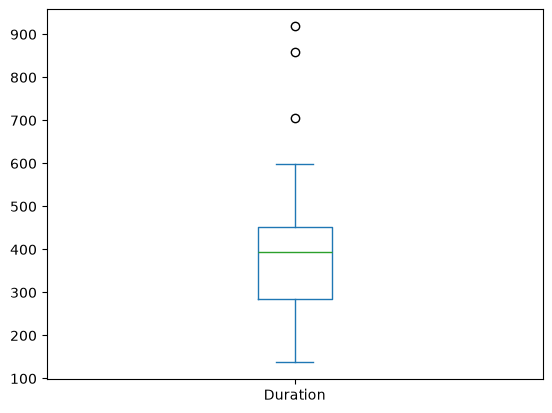

In [26]:
#Created Forced Choice DF

# Create preference dataframe
df_fc = df.filter(like='Preference').copy()
df_fc['Duration'] = df['Duration (in seconds)']
df_fc['Participant'] = df_fc.index

print(df_fc.shape)

# Drop NA rows based on Preference columns only
df_fc = df_fc.dropna(how='all', subset=df.filter(like='Preference').columns.tolist())

print(df_fc.shape)

df_fc.Duration.plot.box()

df_fc = df_fc[df_fc['Duration']<600]

print('Final Shape: ', df_fc.shape)

In [27]:
import pandas as pd

pref_cols = [c for c in df_fc.columns if c.startswith("Preference")]

long = (
    df_fc.melt(id_vars=["Participant", "Duration"],
            value_vars=pref_cols,
            var_name="col", value_name="pref")
    .dropna(subset=["pref"])          # drop pairs the participant never saw
)

parts = long["col"].str.extract(r"Preference (\d+) (D\d)")
long["question"] = parts[0].astype(int)
long["dataset"]  = parts[1].map({"D1": "telco", "D2": "medical"})  # confirm mapping
long["item"]     = long["dataset"] + "_Q" + long["question"].astype(str)
long["choice"]   = (long["pref"] == '2').astype(int)   # 1 = co-optimised, 0 = informative

long = long[["Participant", "dataset", "item", "question", "choice", "Duration"]]
long.columns = ["participant", "dataset", "item", "question", "choice", "duration"]

long.to_csv("comparative_long.csv", index=False)

In [28]:
# Should be 5 trials per participant per dataset
print(long.groupby(["participant", "dataset"]).size().value_counts())

# Should reproduce Table 4 (telco 185/300, medical 200/300 co-optimised)
print(long.groupby("dataset")["choice"].agg(["sum", "count", "mean"]))

# Per-question counts (compare with Table 4 rows)
print(long.pivot_table(index="question", columns="dataset",
                       values="choice", aggfunc=["sum", "count"]))

5    120
Name: count, dtype: int64
         sum  count      mean
dataset                      
medical  200    300  0.666667
telco    185    300  0.616667
             sum         count      
dataset  medical telco medical telco
question                            
1             26    18      31    31
2             18    20      31    30
3             23    21      30    30
4             27    23      31    31
5             11    17      26    28
6             19    12      31    29
7             15    17      32    32
8             20    19      29    30
9             20    19      29    28
10            21    19      30    31


In [54]:
# Split by dataset, keeping Duration/Participant explicitly
df_fc_d1 = df_fc.filter(like='D1').dropna(how = 'all')
df_fc_d2 = df_fc.filter(like='D2').dropna(how = 'all')

#Now count number of preferences per dataset
def generate_dictionary(data):
    data_dict = {1: 0, 2: 0}
    for col in data.filter(like='Preference').columns:
        data_dict[1] += int(data[col].value_counts()['1'])
        data_dict[2] += int(data[col].value_counts()['2'])
        
    return data_dict

print('Telco Dictionary: ', generate_dictionary(df_fc_d1), '\n',
    'Medical Dictionary: ', generate_dictionary(df_fc_d2))

#Get per item counts
def per_item_counts(data):
    count_dic = {}
    for col in data.filter(like='Preference').columns:
        
        count_dic[col] = [int(data[col].value_counts()['1']), int(data[col].value_counts()['2'])]
        
    count_df = pd.DataFrame(count_dic, index=['Informative', 'Co-Optimised'])
    count_df['Sum'] = count_df.sum(axis = 1)
    count_df['Mean'] = count_df.iloc[:, :-1].mean(axis = 1)
    count_df['SD'] = count_df.iloc[:, :-2].std(axis = 1)
    
    #Retain response time
    

    return count_df

per_item_counts(df_fc_d1).to_csv('Counts_Output_Phone.csv')
per_item_counts(df_fc_d2).to_csv('Counts_Output_Medical.csv')

Telco Dictionary:  {1: 115, 2: 185} 
 Medical Dictionary:  {1: 100, 2: 200}


(60, 402)


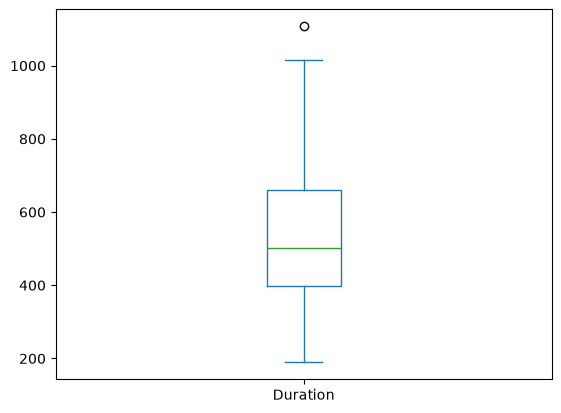

In [55]:
#Repeat data cleaning for Scale Data
scale_df = df.filter(like = "Scale")
scale_df['Duration'] = df['Duration (in seconds)']
scale_df['Participant'] = scale_df.index

scale_df = scale_df.dropna(how='all', subset=df.filter(like='Scale').columns.tolist())

scale_df.Duration.plot.box() #Let's remove the outlier on the high end
print(scale_df.shape)
scale_df = scale_df[scale_df['Duration']<1100]


In [56]:
scale_df_d1 = scale_df.filter(like='D1').dropna(how = 'all')
scale_df_d2 = scale_df.filter(like='D2').dropna(how = 'all')

In [57]:
#Which questions need to be reverse coded? 2, 3, 4, 5, 7, 8
def reverse_code(data):
    item_list = [2, 3, 4, 5, 7, 8]
    map_dict = {'1': '5', '2': '4', '4': '2', '5': '1'}  # 3 -> 3 is a no-op

    for col in data.columns:
        item_num = int(col.split('_')[-1])
        if item_num in item_list:
            data[col] = data[col].replace(map_dict)

    return data

scale_df_d1_re = reverse_code(scale_df_d1)
scale_df_d2_re = reverse_code(scale_df_d2)
        

In [58]:
import regex as re
def parse_col(col):
    pattern = re.compile(r'Scale (\w+) Q(\d+) ([TC])_(\d+)')
    m = pattern.match(col)
    if m:
        dataset, question, ttype, item = m.groups()
        return pd.Series([dataset, question, ttype, int(item)])
    return pd.Series([None, None, None, None])

def convert_to_analyse(data):
    data = data.reset_index().rename(columns={'index': 'Participant'})

    
    long_df = data.melt(id_vars='Participant', var_name='col', value_name='Score')
    
    long_df[['Dataset', 'Question ID', 'Type', 'Item']] = long_df['col'].apply(parse_col)
    long_df = long_df.dropna(subset=['Dataset'])
    
    type_map = {'T': 'Traditional', 'C': 'Co-optimised'}
    long_df['Explanation Type'] = long_df['Type'].map(type_map)
    
    long_df['Score'] = pd.to_numeric(long_df['Score'])
    
    result = (
    long_df
    .groupby(['Participant', 'Dataset', 'Question ID', 'Explanation Type'])['Score']
    .agg(Total_Score='sum', Average_Score='mean')
    .reset_index())
    
    result = result.rename(columns={
    'Total_Score': 'Total Score',
    'Average_Score': 'Average Score'})
    
    result.dropna(subset=['Average Score'], inplace=True)
    
    result.drop('Dataset', axis = 1, inplace = True)
    
    result = result.reset_index(drop = True)
    return result
        
convert_to_analyse(scale_df_d1_re).to_csv('Scale_D1_Final.csv')
convert_to_analyse(scale_df_d2_re).to_csv('Scale_D2_Final.csv')


In [59]:
final_d1 = convert_to_analyse(scale_df_d1_re)
final_d2 = convert_to_analyse(scale_df_d2_re)

/var/folders/zx/gsz4_5_j503dtlrpbycfywq40000gp/T/ipykernel_18121/4064858252.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined, x='Group', y='Total Score', order=order,


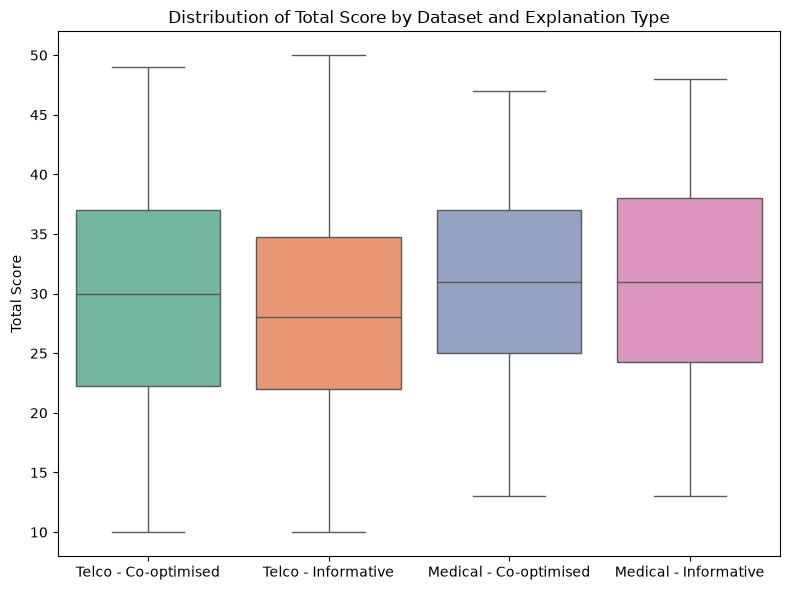

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add a dataset label to each dataframe
final_d1 = final_d1.copy()
final_d2 = final_d2.copy()
final_d1['Dataset'] = 'Telco'
final_d2['Dataset'] = 'Medical'

# Combine
combined = pd.concat([final_d1, final_d2], ignore_index=True)

# Relabel 'Traditional' -> 'Informative'
combined['Explanation Type'] = combined['Explanation Type'].replace(
    {'Traditional': 'Informative'}
)

# Create a combined category so the x-axis shows all four groups
combined['Group'] = combined['Dataset'] + ' - ' + combined['Explanation Type']

# Set explicit order so it goes d1 co-optimised, d1 informative, d2 co-optimised, d2 informative
order = ['Telco - Co-optimised', 'Telco - Informative', 'Medical - Co-optimised', 'Medical - Informative']

plt.figure(figsize=(8, 6))
sns.boxplot(data=combined, x='Group', y='Total Score', order=order,
            palette='Set2')
# sns.stripplot(data=combined, x='Group', y='Total Score', order=order,
#               color='black', alpha=0.4, jitter=True, size=4)

plt.title('Distribution of Total Score by Dataset and Explanation Type')
plt.xlabel('')
plt.ylabel('Total Score')
plt.xticks()
plt.tight_layout()
plt.show()

In [61]:
final_d1.groupby('Explanation Type')['Total Score'].max()['Co-optimised'] - final_d1.groupby('Explanation Type')['Total Score'].max()['Traditional']

np.float64(-1.0)

In [62]:
final_d2.groupby('Explanation Type')['Total Score'].max()['Co-optimised'] - final_d2.groupby('Explanation Type')['Total Score'].max()['Traditional']

np.float64(-1.0)

In [19]:
len(final_d2.Participant.value_counts())

59

In [21]:
final_d2.shape

(236, 6)